# <center> Практические задания по цифровой обработке сигналов </center>
# <center> Первая лабораторная работа </center>


В данной работе Вы познакомитесь с основными методами работы с аудиоданными в Python. Разбересь в том, как работает свертка, и примените пару интересных фильтров.

# Задание 1. Работа с аудиофайлами в Python (1 балл)

## Теория

Звук - это аналоговый сигнал. То есть он является непрерывным по времени и по значениям. Для того, чтобы работать со звуком на цифровом устройстве, надо преобразовать его в цифровое представление. Для этого надо разделить непрерывный сигнал на промежутки времени (дискретизация сигнала) и разбить непрерывные значения на интервалы (квантование сигнала). Выбраные параметры дискретизации и квантования сигнала напрямую влияют на качество цифрового сигнала. 


## Практика

1. Что хранится в .wav файле? Как узнать параметры дискретизации и квантования .wav файла? 

2. Запишите аудиофайл со своим голосом. Загрузите его. Попробуйте поменять ему частоту дискретизации. Нарисуйте форму волны считанного файла. Воспроизведите полученные сигналы. При какой частоте дискретизации становится невозможно разобрать человеческую речь?   

3. Чем .wav отличается от других кодеков, например .mp3 или .ogg?


### Подсказка

Записать цифровой сигнал можно при помощи, например, [Audacity](https://www.audacityteam.org) или [Adobe Audition](https://www.adobe.com/ru/products/audition.html). Для считывания файлов воспользуйтесь библиотекой [scipy](https://www.scipy.org) или [librosa](https://librosa.org/doc/latest/index.html). Для воспроизведения аудиофайла удобно использовать класс Audio из модуля IPython.display, а для отрисовки - matplotlib.

In [3]:
import matplotlib.pyplot as plt 
import numpy as np
import scipy.signal
from scipy.io import wavfile
import IPython.display as ipd

%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# ['retina', 'png', 'jpeg', 'svg', 'pdf']

## 1.1 

wav-файл состоит из двух областей. Одна из них — заголовок файла, другая — область (блок) данных. 

В **заголовке файла** хранится информация о:

- размере файла
- количестве каналов
- частоте дискретизации
- количестве бит в сэмпле ("глубине звучания")

Амплитуда громкости звука в коротком промежутке времени выражается числом, которое, как правило, занимает в файле 8, 16, 24, 32 бита. Совокупность амплитуды и короткого промежутка времени — это сэмпл. Сэмплы содержатся в **блоке данных** файла. В моно варианте сэмплы располагаются последовательно. В стерео же обычно сначала идет значение амплитуды для левого канала, затем для правого, и т.д.

## 1.2

In [4]:
wav_fname = 'gettysburg10.wav'
voice_sr, voice = wavfile.read(wav_fname)

print(f'channels: {voice.ndim}')
print(f'duration: {voice.shape[0] / voice_sr:.2f} s')
print(f'sample rate: {voice_sr} Hz')
print(f'quantization: {voice.dtype}')

channels: 1
duration: 10.00 s
sample rate: 22050 Hz
quantization: int16


Один канал, частота дискретизации 22.05 кГц, квантование 16 бит на отсчёт.

Форма волны загруженного сигнала:

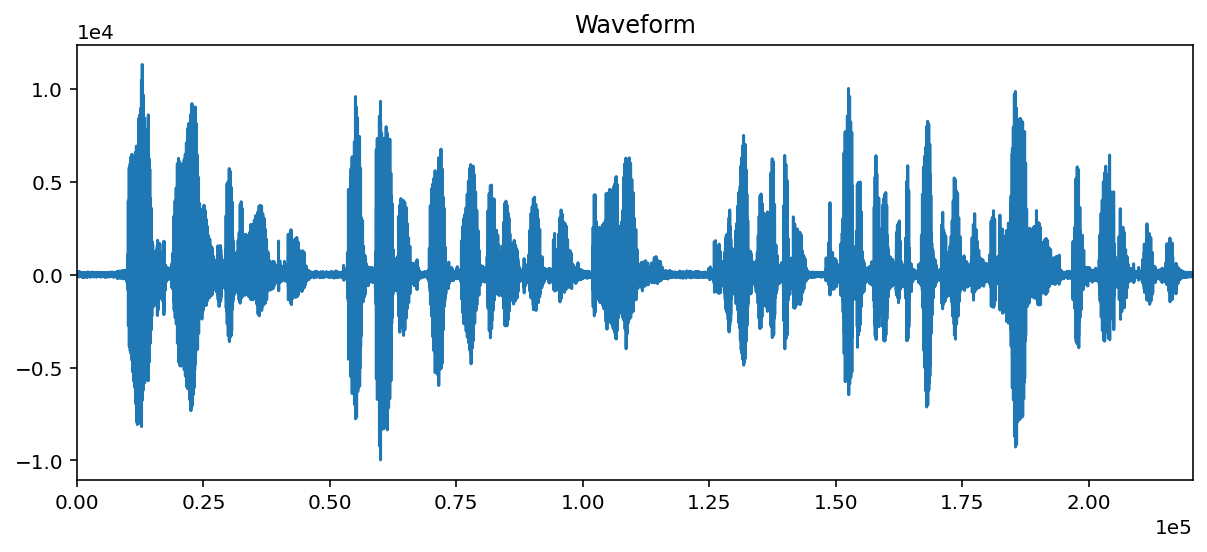

In [5]:
plt.figure(figsize=(10, 4))
plt.plot(voice)
plt.title('Waveform')
ax = plt.gca()
ax.ticklabel_format(style='sci', axis='both', scilimits=(0, 0))
ax.set_xlim(0, voice.shape[0])
plt.show()

Загруженный сигнал с различными частотами дискретизации:

In [6]:
print(f'sample rate: {voice_sr} Hz')
ipd.Audio(data=voice, rate=voice_sr)

sample rate: 22050 Hz


In [7]:
# Уменьшим частоту дискретизации в 1.25 раз, речь ещё можно разобрать
print(f'sample rate: {voice_sr / 1.25} Hz')
ipd.Audio(data=voice, rate=voice_sr / 1.25)

sample rate: 17640.0 Hz


In [8]:
# Уменьшим частоту дискретизации в 2 раза, речь практически невозможно разобрать
print(f'sample rate: {voice_sr / 2} Hz')
ipd.Audio(data=voice, rate=voice_sr / 2)

sample rate: 11025.0 Hz


In [9]:
# Уменьшим частоту дискретизации в 4 раза, речь невозможно разобрать
print(f'sample rate: {voice_sr / 4} Hz')
ipd.Audio(data=voice, rate=voice_sr / 4)

sample rate: 5512.5 Hz


In [10]:
# Увеличим частоту дискретизации в 2 раза, речь сложно разобрать, но возможно
print(f'sample rate: {voice_sr * 2} Hz')
ipd.Audio(data=voice, rate=voice_sr * 2)

sample rate: 44100 Hz


In [11]:
# Увеличим частоту дискретизации в 4 раза, речь разобрать невозможно
print(f'sample rate: {voice_sr * 4} Hz')
ipd.Audio(data=voice, rate=voice_sr * 4)

sample rate: 88200 Hz


## 1.3

Основное отличие .wav от других кодеков (.mp3 или .ogg) состоит в том, что wav — это формат без сжатия (большой размер файлов, лучше качество), а mp3 и ogg — это форматы со сжатием/потерями (малый размер файлов, качество ниже).

# Задание 2. Гармонические сигналы (1 балл)

## Теория
[Гармонические колебания](https://ru.wikipedia.org/wiki/Гармонические_колебания) -  колебания, при которых физическая величина изменяется с течением времени по гармоническому (синусоидальному/косинусоидальному) закону. 

В общем случае гармонические колебания задаются формулой:

$$y=A \cos(\omega t+\varphi_0)$$

где $А$ - это амплитуда, $\omega$ – циклическая частота (радиан/с), $\varphi$ - фаза (сдвиг), $t$ – время. 


In [12]:
# Сначала определим функцию для отрисовки сигнала с хорошим масштабом и сеткой
# Это поможет легче анализировать сигнал
def draw_signal(data, figsize=(14, 14)):
    plt.figure(figsize=figsize)
    plt.plot(data, linewidth=2)
    plt.minorticks_on()
    plt.xticks(np.arange(0, 1000, step=100))
    plt.yticks(np.arange((data.min().round())//10*10, 
                         (data.max().round())//10*10+10, step=5))
    plt.grid(which='major',
        color = 'k', 
        linewidth = 1)
    plt.grid(which='minor', 
        color = 'k', 
        linestyle = ':')
    plt.show()

In [13]:
# Читаем данные с подготовленными сигналами
import pickle
with open("resources/data.pickle", "rb") as f:
    test_data = pickle.load(f)
# Теперь можно приступать к практике!

## Практика

Постройте графики трех сигналов a, b и c из test_data['task2']. Попробуйте подобрать коэффициенты для этих сигналов. Сгенерируйте сигналы (1000 отсчетов) с подобранными коэффициентами. Постройте графики сгенерированных сигналов и пройдите тест на схожесть с оригинальным.


Подсказка. Фаза, период и амплитуда сигнала - целочисленные. Для генерации пользуйтесь библиотекой numpy и функциями arange, sin, cos.

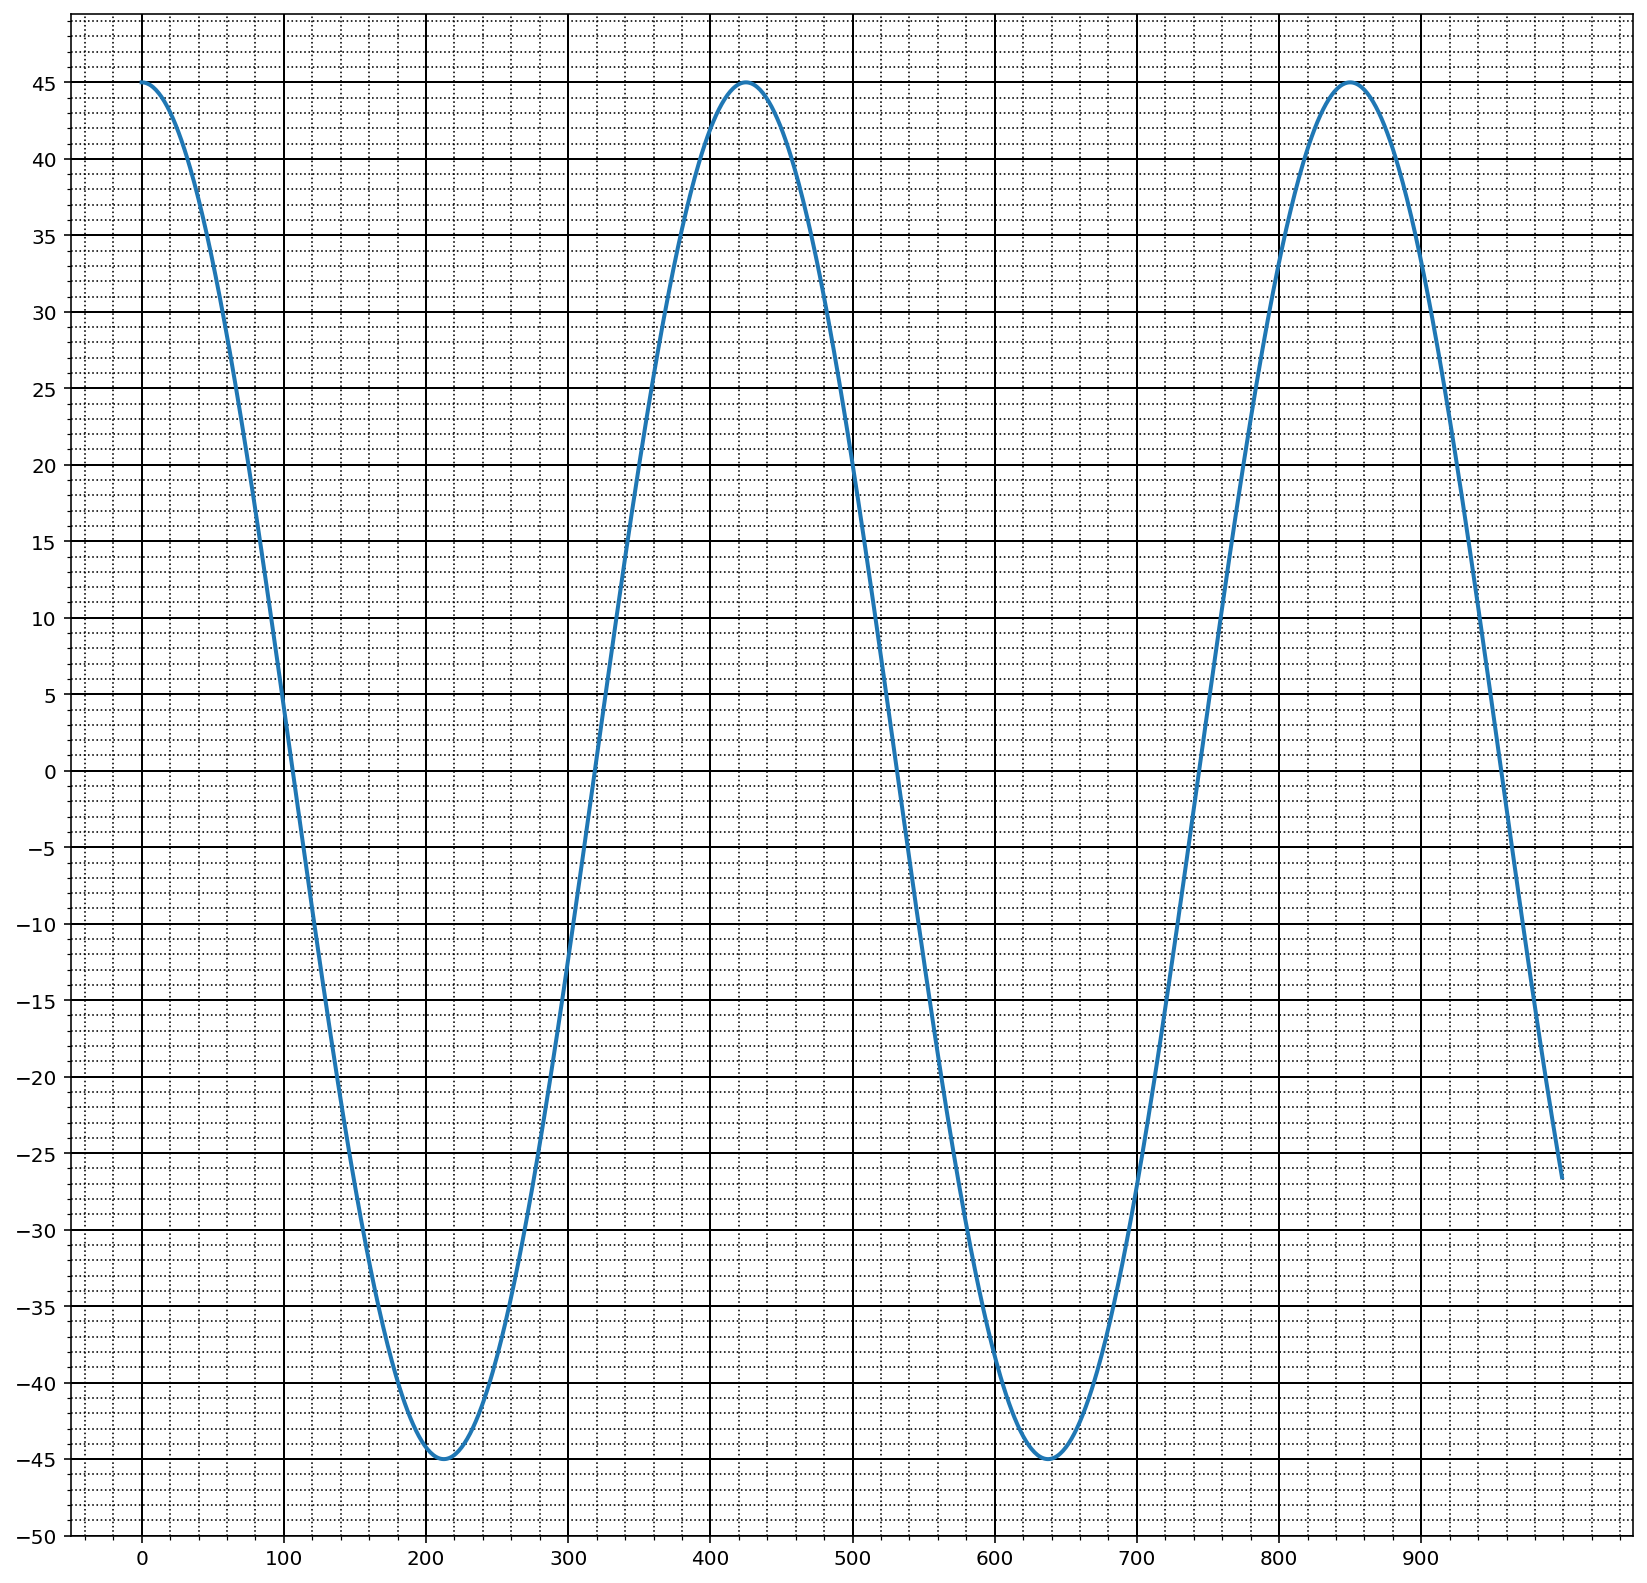

In [14]:
draw_signal(test_data['task2']['a'])

In [15]:
a = 45 * np.cos(2 * np.pi * np.arange(1000) / 425) # T = 425 ms (possible value)
# a = 45 * np.cos(2 * np.pi * 2.353 [Hz] / 1000 * np.arange(1000))

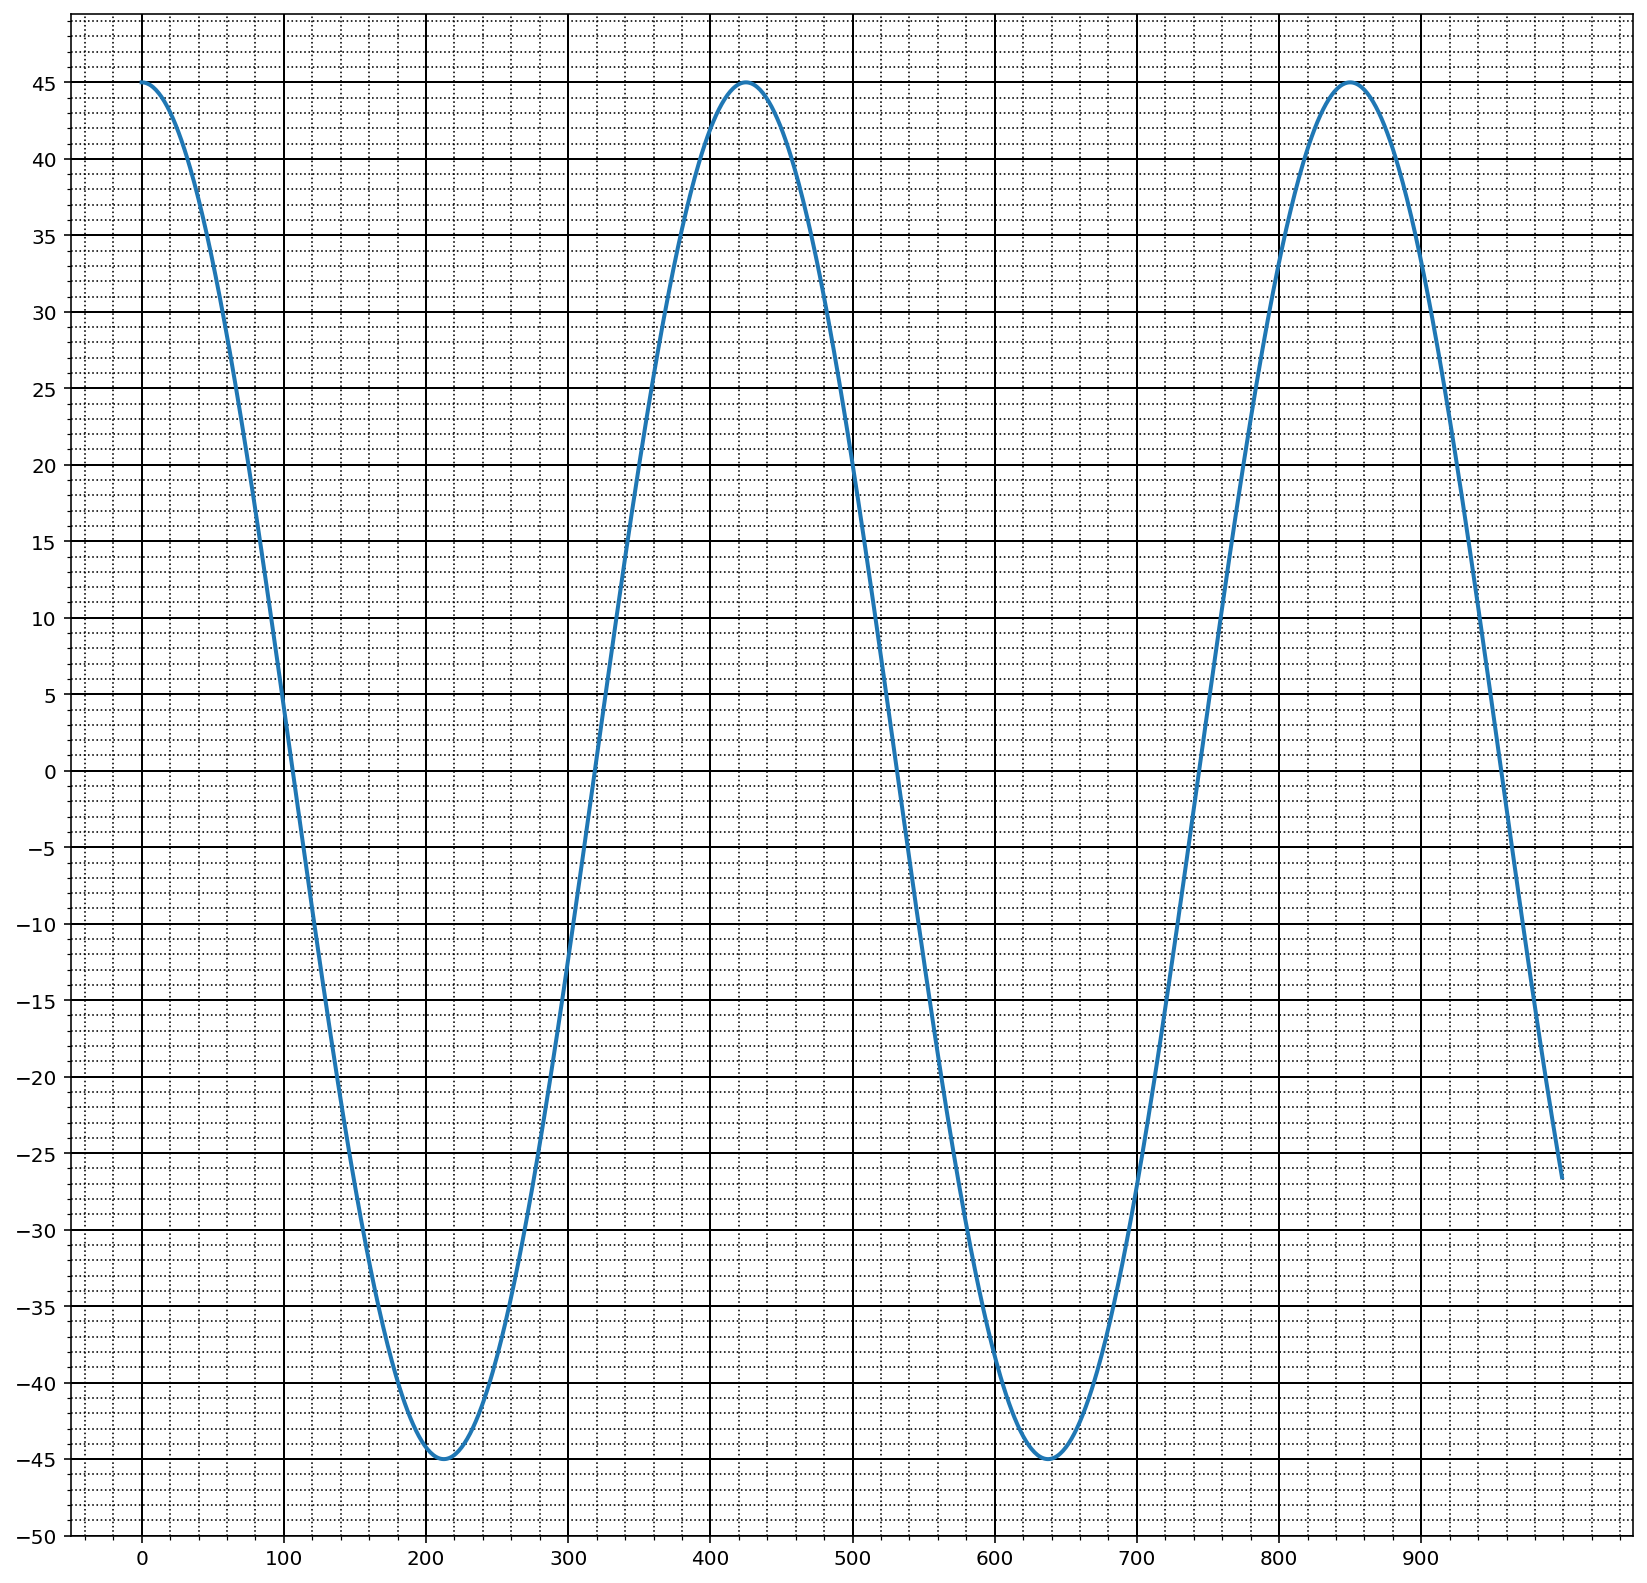

In [16]:
draw_signal(a)

In [17]:
assert len(a) == 1000
assert np.allclose(a, test_data["task2"]["a"], atol=1)
print("Ok!")

Ok!


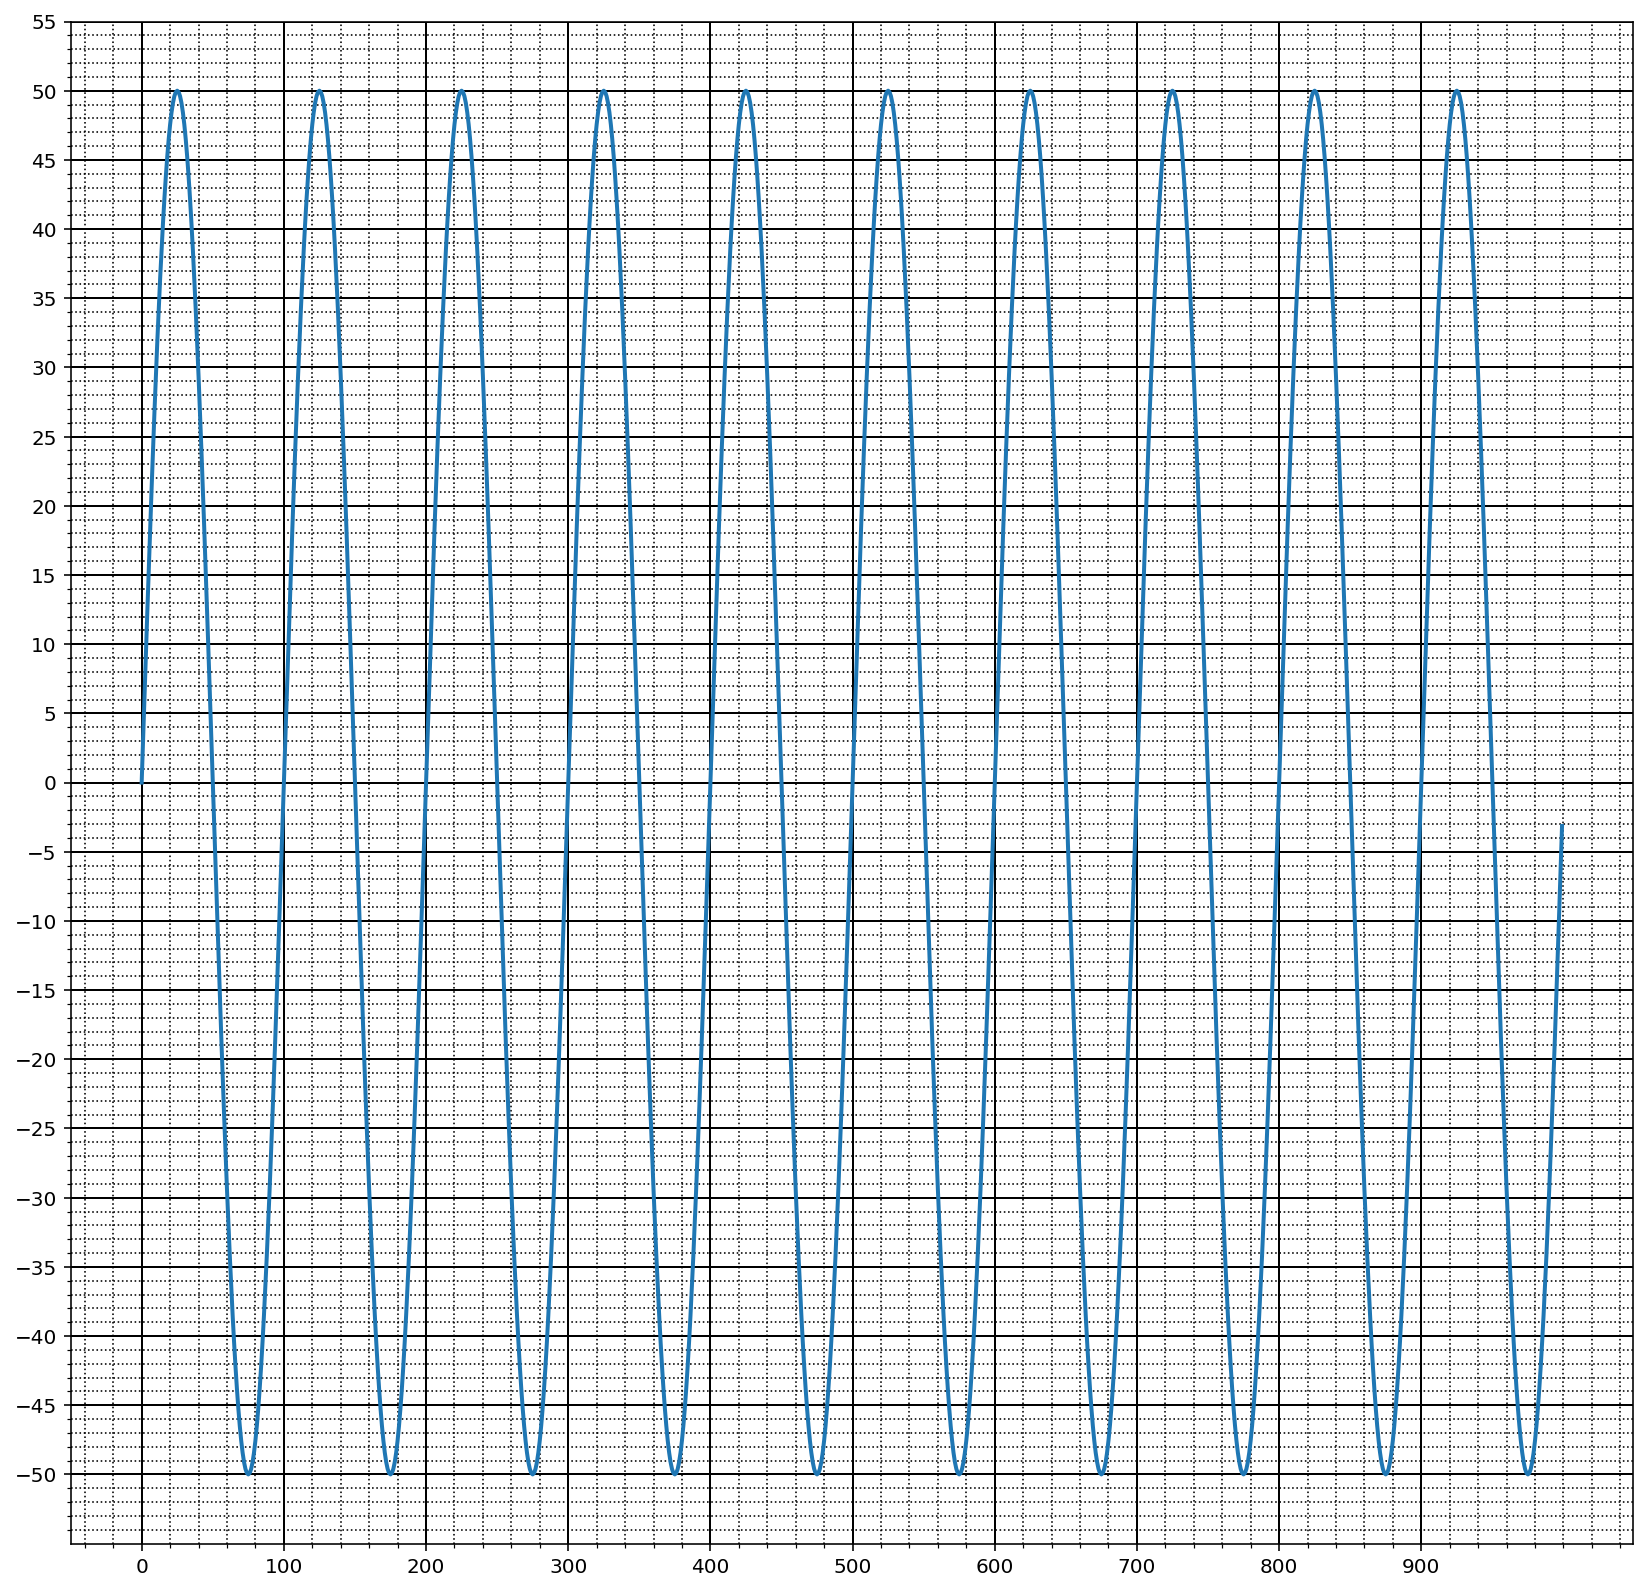

In [18]:
draw_signal(test_data['task2']['b'])

In [19]:
b = 50 * np.sin(2 * np.pi * np.arange(1000) / 100) # T = 100 ms (possible value)
# b = 50 * np.sin(2 * np.pi * 10 [Hz] / 1000 * np.arange(1000))

In [20]:
assert len(b)== 1000
assert np.allclose(b, test_data["task2"]["b"], atol=1)
print("Ok!")

Ok!


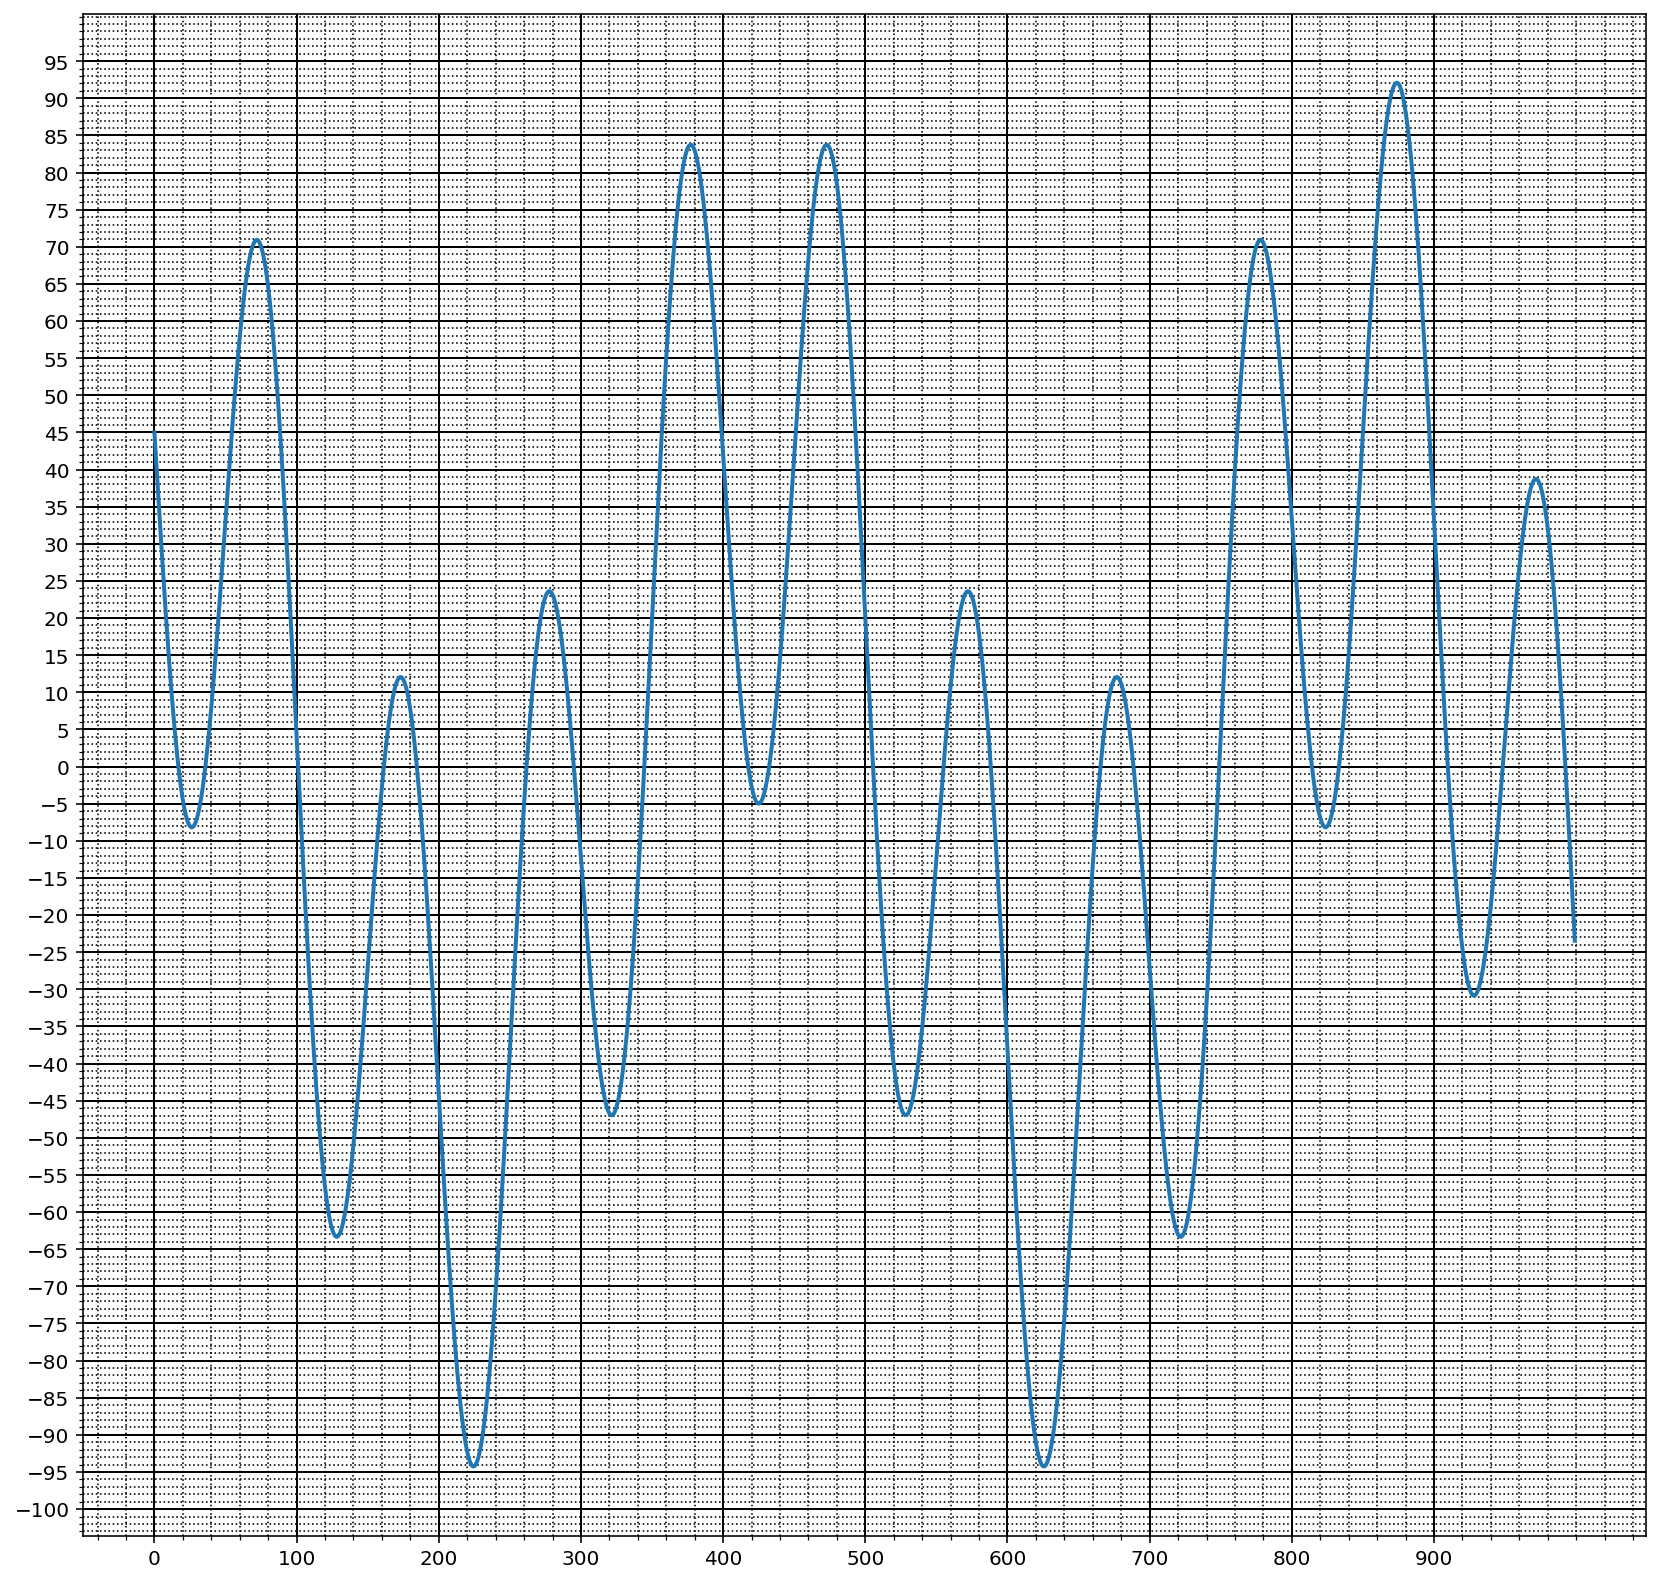

In [21]:
draw_signal(test_data['task2']['c'])

In [22]:
# сигнал состоит из двух гармоник
c = ( 45 * np.cos(2 * np.pi * np.arange(1000) / 425) + 
      50 * np.sin(2 * np.pi * np.arange(1000) / 100 + np.pi) )

In [23]:
assert len(c)== 1000
assert np.allclose(c, test_data["task2"]["c"], atol=1)
print("Ok!")

Ok!


# Задание 3. Свертка (3 балла)

## Теория
Одна из наиболее частых операций, которая выполняется при обработке сигналов, это свёртка. Свёртка имеет много различных применений, например, с ее помощью можно убрать из сигнала шумы или применить к сигналу эффект эхо.


Свёртка — это математическая операция, применённая к двум функциям f и g и порождающая третью функцию. Операцию свёртки можно интерпретировать как «схожесть» одной функции с отражённой и сдвинутой копией другой.  Другими словами, преобразование свёртки однозначно определяет выходной сигнал y(t) для установленного значения входного сигнала x(t) при известном значении функции импульсного отклика системы h(t).

![Convolution](resources/Convolution_of_box_signal_with_itself2.gif "Convolution")

Формула свёртки:
$$y_t=\frac{1}{2} \int_0^T x(\tau)h(t-τ)dτ$$
где $\tau$  - длительность импульсной переходной характеристики.

## Практика
Реализуйте операцию свёртки. Сравните её с существующей реализацией scipy.signal.convolve. Постройте графики фильтра, исходного сигнала и результата свертки.

In [24]:
def convolve(in1, in2):
    N = len(in1) + len(in2) - 1
    result = np.zeros(N)
    # zero padding
    in1_p = np.pad(in1, (0, N - len(in1)), 'constant')
    in2_p = np.pad(in2, (0, N - len(in2)), 'constant') 
    # linear convolution
    for n in range(N):
        for k in range(N):
            if n >= k:
                result[n] = result[n] + in1_p[n - k] * in2_p[k]       
    return result

In [25]:
def test_convolve(a, b, print_debug=False):
    my_result = convolve(a, b)
    scipy_result = scipy.signal.convolve(a, b, method='direct')
    if print_debug:
        print(f"Your result {my_result}")
        print(f"Scipy result {scipy_result}")
    assert np.allclose(my_result, scipy_result), f"Test {a} conv {b} failed"
    print("Ok!")

In [26]:
a = np.repeat([0,1,0], 10)
b = np.array([0,1,2,3,2,1,0])

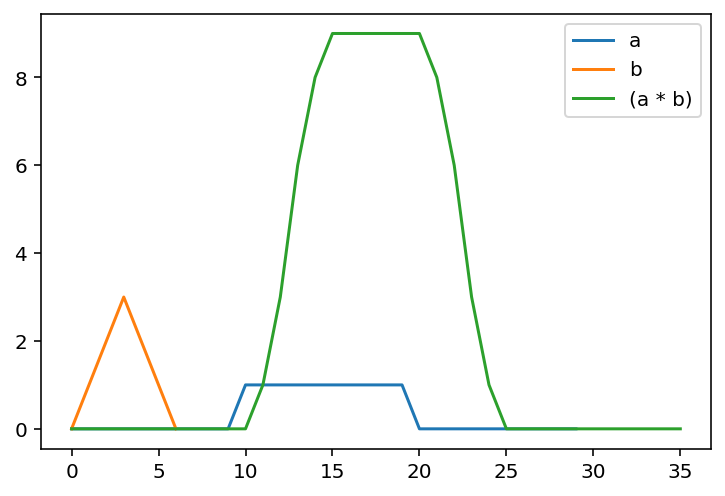

In [27]:
# Нарисуйте результат свертки a и b
plt.plot(a, label='a')
plt.plot(b, label='b')
plt.plot(convolve(a, b), label='(a * b)')
plt.legend()
plt.show()

In [28]:
test_convolve(a, b, print_debug=False)

Ok!


# Задание 5. * Алгоритм Карплуса-Стронга 

Реализуйте  [Алгоритм Карплуса-Стронга](https://en.wikipedia.org/wiki/Karplus%E2%80%93Strong_string_synthesis). В качестве фильтра используйте усреднитель двух смежных отсчетов. Проверьте результат. 

Отрисуйте и воспроизведите полученный сигнал. На что влияют параметры генерации? Попробуйте имитировать звучание разных струн гитары.

In [29]:
def karplus_strong(noise, N):
    # Noise - input
    # N - number of samples to generate
    # return y - generated signal based on Noise
    
    noise_c = noise.copy() 
    y = []
    cur_sample = 0
    prev_value = 0
    
    while len(y) < N:
        y.append(noise_c[cur_sample])
        noise_c[cur_sample] = (noise_c[cur_sample] + prev_value) / 2
        prev_value = y[-1]
        cur_sample += 1
        cur_sample = cur_sample % noise_c.size
    
    return np.array(y)

In [30]:
sample_rate = 22050 # [Hz]
frequency = 100 # [Hz]
duration = 2 # [s]
noise = 2 * np.random.uniform(-1, 1, int(sample_rate / frequency))
gen_wav = karplus_strong(noise, sample_rate * duration)
ipd.Audio(gen_wav, rate=sample_rate)

In [31]:
np.random.seed(seed=1)
sample_rate = 44100
frequency = 82.41
sec = 2
gen_len = sample_rate * sec
noise = (2 * np.random.uniform(-1, 1, int(sample_rate/frequency))) # [-1, 1]

gen_wav = karplus_strong(noise, gen_len)
assert np.allclose(gen_wav[:len(noise)], noise), "Generated signal must starting with noise"
assert np.allclose(gen_wav[len(noise)], (noise[0])/2), "Out of range samples eq 0."
assert np.allclose(gen_wav[len(noise)+1: 2*len(noise)], (noise[:-1] + noise[1:])/2), \
    "Bad requrent rule( 1 iteration)"
assert np.allclose(gen_wav[2*len(noise)], (noise[0]/2 + noise[-1])/2), \
    "Bad requrent rule( 2 iteration)"
assert np.allclose(gen_wav[2*len(noise)+2: 3*len(noise)], \
                   (((noise[:-1] + noise[1:])/2)[:-1] + ((noise[:-1] + noise[1:])/2)[1:])/2), \
    "Bad requrent rule( 3 iteration)"
print('All Ok!')

All Ok!


In [181]:
# Попробуйте покрутить параметры генерации.
sample_rate = 44100
duration = 1
freqs = np.logspace(0, 1, num=8, base=2) * 400

for freq in freqs:
    print(f'f = {freq:.2f} Hz')
    noise = (2 * np.random.uniform(-1, 1, int(sample_rate / freq)))
    gen_wav = karplus_strong(noise, sample_rate * duration)
    display(ipd.Audio(gen_wav, rate=sample_rate))

f = 400.00 Hz


f = 441.64 Hz


f = 487.61 Hz


f = 538.36 Hz


f = 594.40 Hz


f = 656.27 Hz


f = 724.58 Hz


f = 800.00 Hz
